In [93]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report as report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet


from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay

from sklearn.neighbors import KNeighborsRegressor as KNNR

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;

from sklearn.ensemble import RandomForestClassifier as RFC;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from yellowbrick.model_selection import LearningCurve

from sklearn.model_selection import LeavePOut;

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

#1 Повторите диагностику модели классификации синтетических данных с использованием других метрик эффективности - precision, recall, F1. Как изменились результаты?

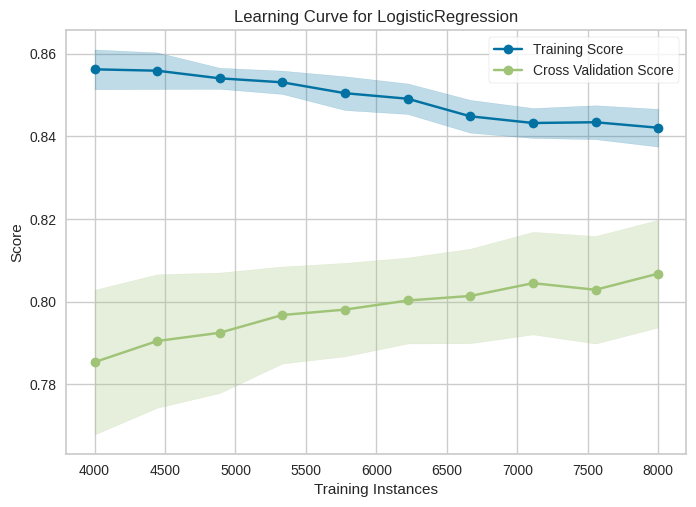

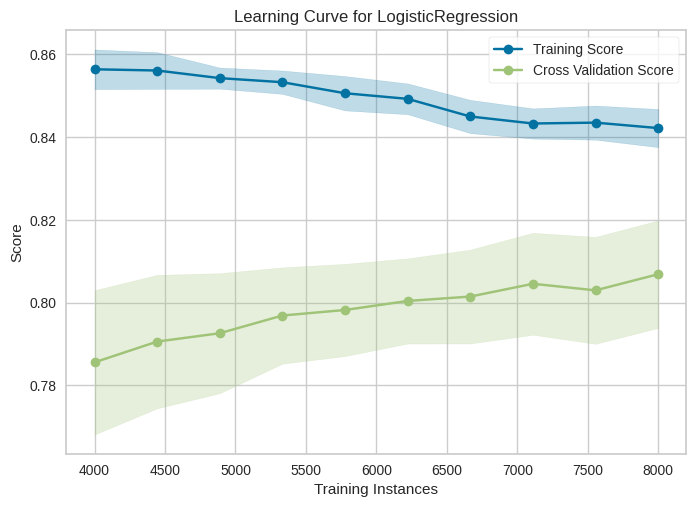

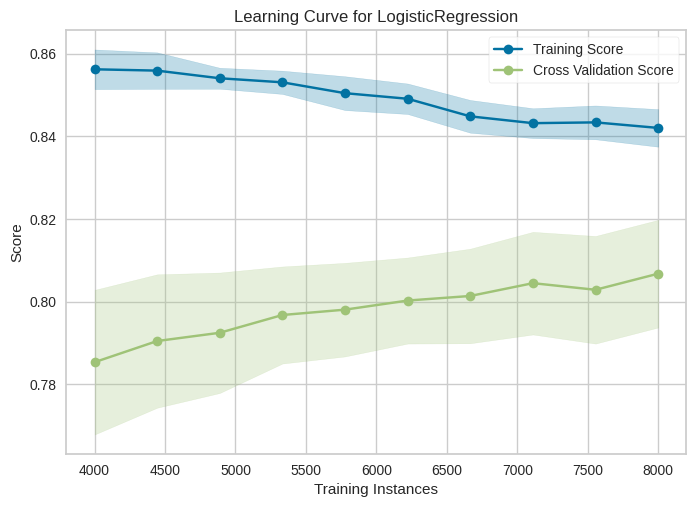

<Axes: title={'center': 'Learning Curve for LogisticRegression'}, xlabel='Training Instances', ylabel='Score'>

In [ ]:
x, y = mc(n_samples=10000, n_features=500,
                           n_informative=50, n_repeated=0,
                           class_sep=1, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    test_size=0.25,
                                                    random_state=3)

#m = LR().fit(x_train,y_train)
'''
fig,axs = plt.subplots(3,1,figsize=(10,20))
LearningCurve(LR(), scoring='recall_macro', ax = axs[0], train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y)
LearningCurve(LR(), scoring='precision_macro', ax = axs[1], train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y)
LearningCurve(LR(), scoring='f1_macro', ax = axs[2], train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y)

plt.show()
'''
LearningCurve(LR(), scoring='recall_macro', train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y).show()
LearningCurve(LR(), scoring='precision_macro', train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y).show()
LearningCurve(LR(), scoring='f1_macro', train_sizes=np.linspace(0.5, 1.0, 10)).fit(x,y).show()


#2 Повторите диагностику модели регрессии с использованием других видов моделей:
метода опорных векторов (исследуйте влияние параметра С на недо-и переобучение)

метода ближайших соседей (исследуйте влияние количества соседей)

метода решающих деревьев (гиперпараметры по вашему выбору)

  0%|          | 0/10 [00:00<?, ?it/s]

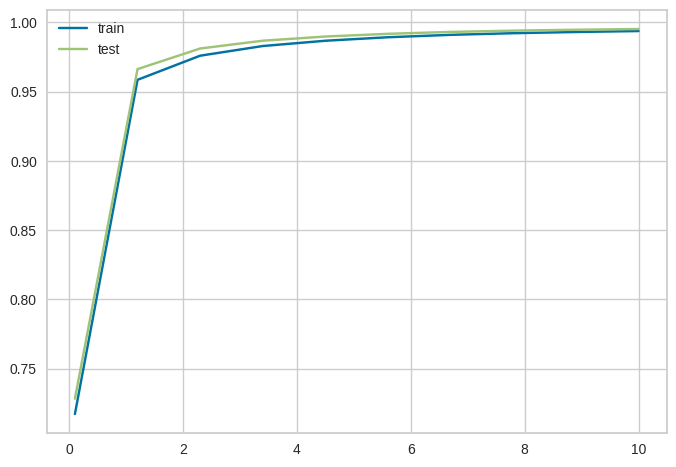

In [ ]:
#svr
x, y = mr(n_samples=10000, n_features=2, noise=1, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    test_size=0.25,
                                                    random_state=3)
xp = np.linspace(0.1,10,10)
ms=[]
for i in tqdm(xp):
  ms.append(SVR(C = i,kernel='rbf').fit(x_train,y_train))

yp_train = [i.score(x_train,y_train) for i in ms]
yp_test = [i.score(x_test,y_test) for i in ms]
plt.plot(xp,yp_train, label="train")
plt.plot(xp,yp_test, label="test")
plt.legend()
plt.show()

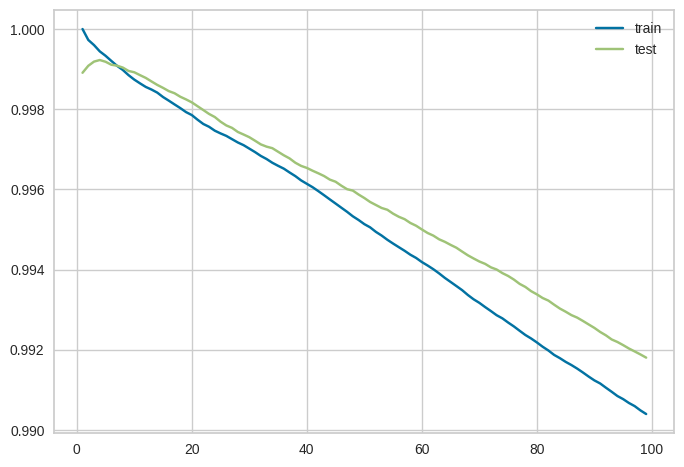

In [ ]:
#knn
x, y = mr(n_samples=10000, n_features=2, noise=1, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    test_size=0.25,
                                                    random_state=3)
xp = np.array(range(1,100))
ms = [KNNR(n_neighbors = i).fit(x_train,y_train) for i in xp]
yp_train = [i.score(x_train,y_train) for i in ms]
yp_test = [i.score(x_test,y_test) for i in ms]
plt.plot(xp,yp_train, label="train")
plt.plot(xp,yp_test, label="test")
plt.legend()
plt.show()

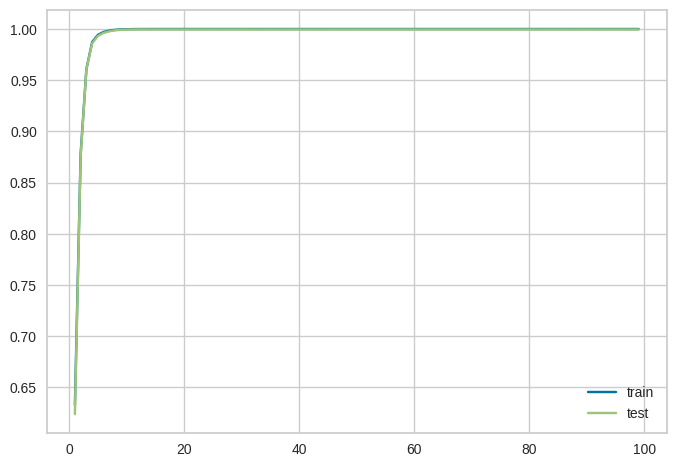

In [ ]:
#dtc
x, y = mr(n_samples=10000, n_features=2, noise=1, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    test_size=0.25,
                                                    random_state=3)
xp = np.array(range(1,100))
ms = [DTR(max_depth = i).fit(x_train,y_train) for i in xp]
yp_train = [i.score(x_train,y_train) for i in ms]
yp_test = [i.score(x_test,y_test) for i in ms]
plt.plot(xp,yp_train, label="train")
plt.plot(xp,yp_test, label="test")
plt.legend()
plt.show()

#3 Дополните анализ датасета Бостон исследованием модели лассо - постройте кривые обучения для переобученной, недообученной и качественной модели, найдите оптимальное значение параметра регуляризации в модели лассо.

<ipython-input-88-902b3c44b4b5>:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  dataset=dataset.fillna(method = 'bfill')


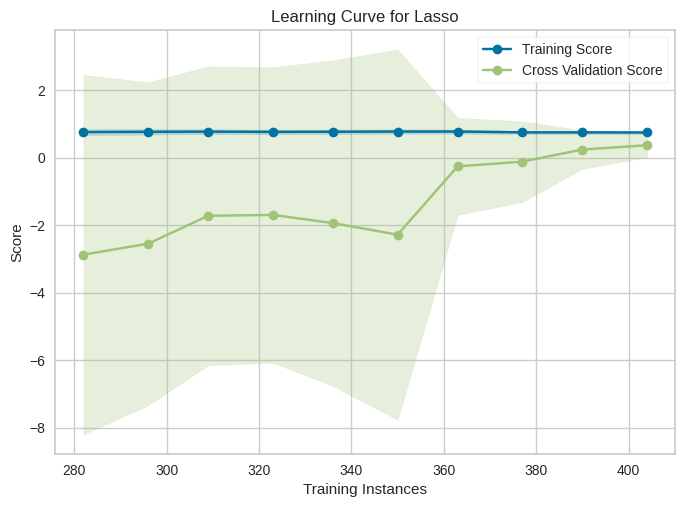

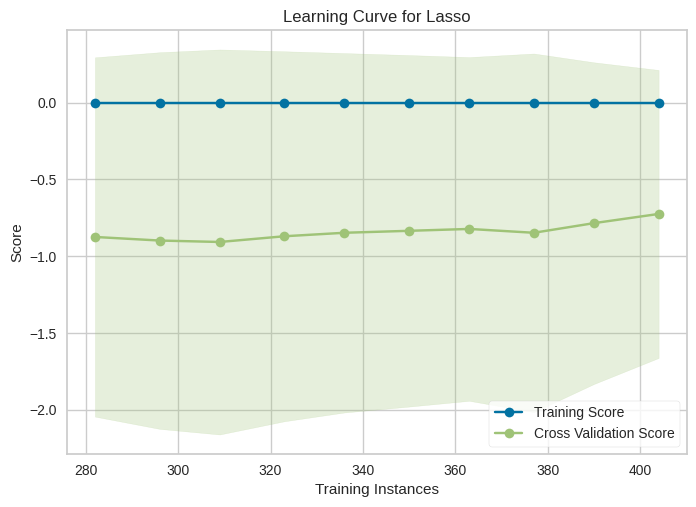

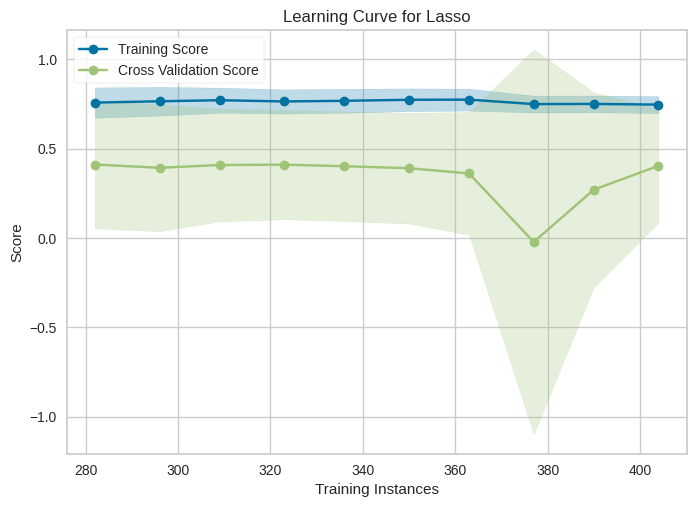

"\nfor i in np.linspace(0.001,10,100):\n  print(i)\n  visualizer = LearningCurve(\n    Lasso(alpha=i), scoring='r2', train_sizes=np.linspace(0.7, 1.0, 10)).fit(x, y) .show()\n"

In [88]:
dataset = pd.read_csv('/content/BostonHousing.csv',delimiter = ',')
#dataset=dataset.dropna()
dataset=dataset.fillna(method = 'bfill')
x = dataset.iloc[:,:-1]
x = pd.DataFrame(SC().fit_transform(x))
y = dataset.iloc[:,-1]
#x_train, x_test, y_train, y_test = train_test_split(
#    x, y, test_size=0.25, random_state=0)
#visualizer = LearningCurve(
#    Lasso(alpha=0.0001), scoring='r2', train_sizes=np.linspace(0.7, 1.0, 10)
#).fit(x, y) .show()

#переобученной
visualizer = LearningCurve(
    Lasso(alpha=0.0001), scoring='r2', train_sizes=np.linspace(0.7, 1.0, 10)
).fit(x, y) .show()
#недообученной
visualizer = LearningCurve(
    Lasso(alpha=100.0), scoring='r2', train_sizes=np.linspace(0.7, 1.0, 10)
).fit(x, y) .show()
#качественной
visualizer = LearningCurve(
    Lasso(alpha=0.05), scoring='r2', train_sizes=np.linspace(0.7, 1.0, 10)
).fit(x, y) .show()


'''
for i in np.linspace(0.001,10,100):
  print(i)
  visualizer = LearningCurve(
    Lasso(alpha=i), scoring='r2', train_sizes=np.linspace(0.7, 1.0, 10)).fit(x, y) .show()
'''

<ipython-input-85-020e34b180cf>:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  dataset=dataset.fillna(method = 'bfill')


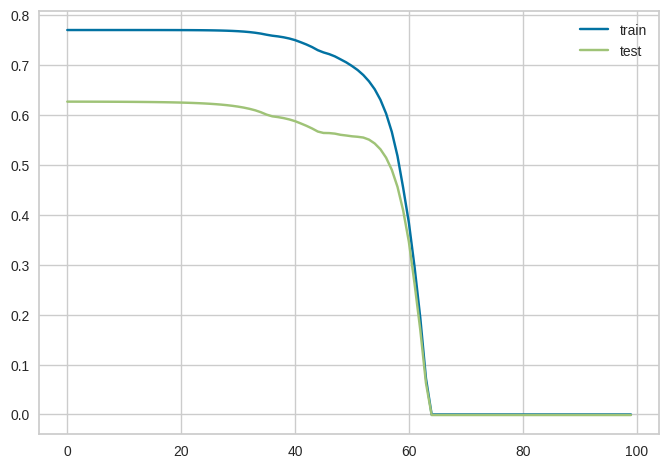

In [85]:
dataset = pd.read_csv('/content/BostonHousing.csv',delimiter = ',')
#dataset=dataset.dropna()
dataset=dataset.fillna(method = 'bfill')
#dataset = pd.DataFrame(SC().fit_transform(dataset))
x = dataset.iloc[:,:-1]
x = pd.DataFrame(SC().fit_transform(x))
y = dataset.iloc[:,-1]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0)
trains = []
tests = []
for i in np.logspace(-3, 3, 100):
  lasso = Lasso(alpha=i).fit(x_train, y_train)
  trains.append(lasso.score(x_train, y_train))
  tests.append(lasso.score(x_test, y_test))

plt.plot(trains, label="train")
plt.plot(tests, label="test")
plt.legend()
plt.show()

<ipython-input-87-3a392d1e4cd6>:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  dataset=dataset.fillna(method = 'bfill')


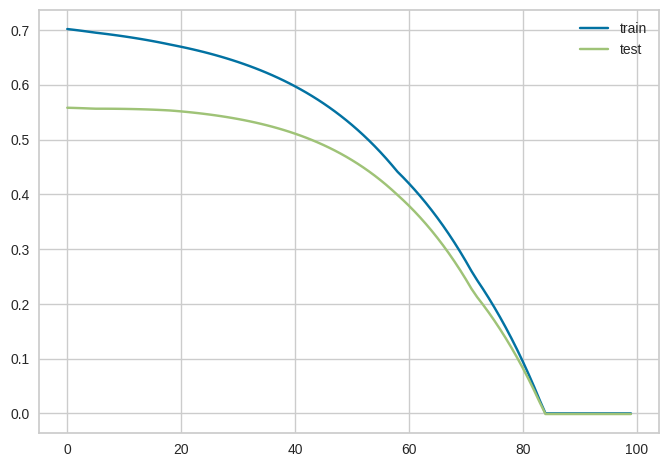

In [87]:
dataset = pd.read_csv('/content/BostonHousing.csv',delimiter = ',')
#dataset=dataset.dropna()
dataset=dataset.fillna(method = 'bfill')
#dataset = pd.DataFrame(SC().fit_transform(dataset))
x = dataset.iloc[:,:-1]
x = pd.DataFrame(SC().fit_transform(x))
y = dataset.iloc[:,-1]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0)
trains = []
tests = []
for i in np.logspace(0, 1, 100):
  lasso = Lasso(alpha=i).fit(x_train, y_train)
  trains.append(lasso.score(x_train, y_train))
  tests.append(lasso.score(x_test, y_test))

plt.plot(trains, label="train")
plt.plot(tests, label="test")
plt.legend()
plt.show()

#4 В одном из двух первых примеров используйте модель ElasticNet и исследуйте влияние сразу двух параметров регуляризации на эффективность модели.

  0%|          | 0/30 [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.265e+03, tolerance: 3.071e+00 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.270e+03, tolerance: 3.071e+00 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_mode

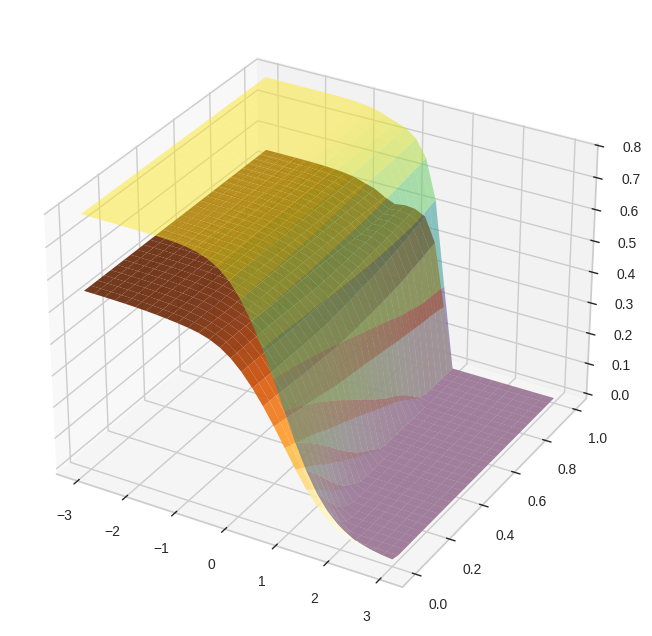

In [81]:
dataset = pd.read_csv('/content/BostonHousing.csv',delimiter = ',')
dataset=dataset.dropna()
#dataset = pd.DataFrame(SC().fit_transform(dataset))
x = dataset.iloc[:,:-1]
x = pd.DataFrame(SC().fit_transform(x))
y = dataset.iloc[:,-1]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0)
trains = []
tests = []

alphas = np.logspace(-3,3,30)
l1_ratios = np.linspace(0, 1, 30)

train_mse_scores = np.zeros((len(alphas), len(l1_ratios)))
test_mse_scores = np.zeros((len(alphas), len(l1_ratios)))

for i1,i in enumerate(tqdm(alphas)):
  for i2,j in enumerate(l1_ratios):
    elastic = ElasticNet(alpha = i, l1_ratio = j).fit(x_train, y_train)
    #trains.append(elastic.score(x_train, y_train))
    #tests.append(elastic.score(x_test, y_test))
    train_mse_scores[i1,i2] = elastic.score(x_train, y_train)
    test_mse_scores[i1,i2] = elastic.score(x_test, y_test)


#plt.plot(trains, label="train")
#plt.plot(tests, label="test")
#plt.legend()
#plt.show()

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

X_grid, Y_grid = np.meshgrid(alphas, l1_ratios)

ax.plot_surface(np.log10(X_grid), Y_grid, train_mse_scores.T, cmap='viridis',alpha=0.5)
ax.plot_surface(np.log10(X_grid), Y_grid, test_mse_scores.T, cmap='YlOrBr',alpha=0.9)
plt.show()

#5 Дополните анализ дерева решений из третьего примера: постройте кривые регуляризации для полного датасета, найдите оптимальную глубину дерева и оцените качество такой модели на всем датасете. Повторите данный анализ используя в качестве метрики эффективности F1.

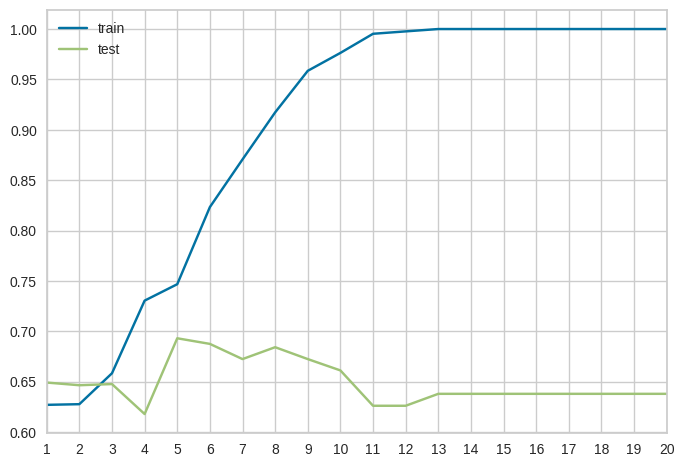

Train score = 0.6584
Test score = 0.6476


In [117]:
df = pd.read_csv('https://raw.githubusercontent.com/koroteevmv/ML_course/2023/ML4.3%20diagnostics/diabetes.csv')
target = "Outcome"
y = df[target]
X = df.drop(target, axis=1)
X = SC().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

trains= []
tests = []
xs = list(range(1,21))

for i in xs:
  dtc = DTC(random_state=1,max_depth=i).fit(X_train, y_train)
  y_train_pred = dtc.predict(X_train)
  y_pred = dtc.predict(X_test)

  trains.append(f1_score(y_train, y_train_pred))
  tests.append(f1_score(y_test, y_pred))

plt.plot(xs,trains, label="train")
plt.plot(xs,tests, label="test")
plt.xlim([1,20])
plt.xticks(xs)
plt.legend()
plt.grid('ON')
plt.show()

model = DTC(random_state=1,max_depth=3).fit(X_train, y_train)
y_train_pred = model.predict(X_train)
y_pred = model.predict(X_test)
from sklearn.metrics import f1_score
print("Train score = %.4f" % f1_score(y_train, y_train_pred))
print("Test score = %.4f" % f1_score(y_test, y_pred))

#6 Повторите анализ на других реальных датасетах из репозитория OpenML:
phoneme

banknote-authentication

delta_ailerons

mammography

electricity

mozilla4

kropt

nursery

volcanoes-b3

  0%|          | 0/3 [00:00<?, ?it/s]

delta_ailerons
**Author**:   
**Source**: Unknown - Date unknown  
**Please cite**:   

Binarized version of the original data set (see version 1). It converts the numeric target feature to a two-class nominal target feature by computing the mean and classifying all instances with a lower target value as positive ('P') and all others as negative ('N').

Downloaded from openml.org.


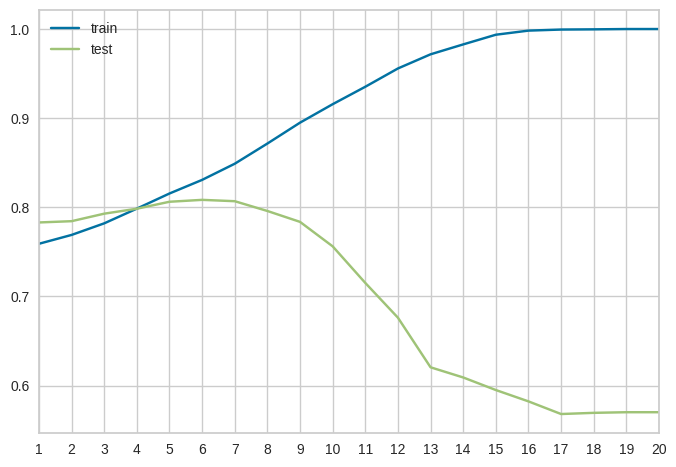

electricity


/usr/local/lib/python3.11/dist-packages/sklearn/datasets/_openml.py:323: UserWarning: Multiple active versions of the dataset matching the name electricity exist. Versions may be fundamentally different, returning version 1. Available versions:
- version 1, status: active
  url: https://www.openml.org/search?type=data&id=151
- version 2, status: active
  url: https://www.openml.org/search?type=data&id=43945

  warn(warning_msg)


**Author**: M. Harries, J. Gama, A. Bifet  
**Source**: [Joao Gama](http://www.inescporto.pt/~jgama/ales/ales_5.html) - 2009  
**Please cite**: None  

**Electricity** is a widely used dataset described by M. Harries and analyzed by J. Gama (see papers below). This data was collected from the Australian New South Wales Electricity Market. In this market, prices are not fixed and are affected by demand and supply of the market. They are set every five minutes. Electricity transfers to/from the neighboring state of Victoria were done to alleviate fluctuations.

The dataset (originally named ELEC2) contains 45,312 instances dated from 7 May 1996 to 5 December 1998. Each example of the dataset refers to a period of 30 minutes, i.e. there are 48 instances for each time period of one day. Each example on the dataset has 5 fields, the day of week, the time stamp, the New South Wales electricity demand, the Victoria electricity demand, the scheduled electricity transfer between states and the 

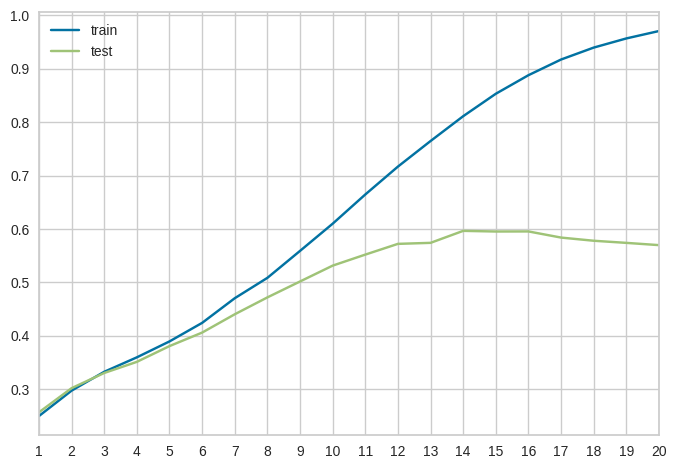

volcanoes-b3
**Author**: Michael C. Burl 
**Source**: UCI  
**Please cite**:   

* Dataset Title:  
Volcanoes on Venus - JARtool experiment Data Set  
Experiment: B3        

* Source:

Michael C. Burl 
MS 126-347, JPL 
4800 Oak Grove Drive 
Pasadena, CA 91109 
(818) 393-5345 
Michael.C.Burl '@' jpl.nasa.gov 
http://www-aig.jpl.nasa.gov/mls/home/burl/


* Data Set Information:  

The data was collected by the Magellan spacecraft over an approximately four year period from 1990--1994. The objective of the mission was to obtain global mapping of the surface of Venus using synthetic aperture radar (SAR). A more detailed discussion of the mission and objectives is available at JPL's Magellan webpage. 

There are some spatial dependencies. For example, background patches from with in a single image are likely to be more similar than background patches taken across different images. 

In addition to the images, there are "ground truth" files that specify the locations of volcanoes within the

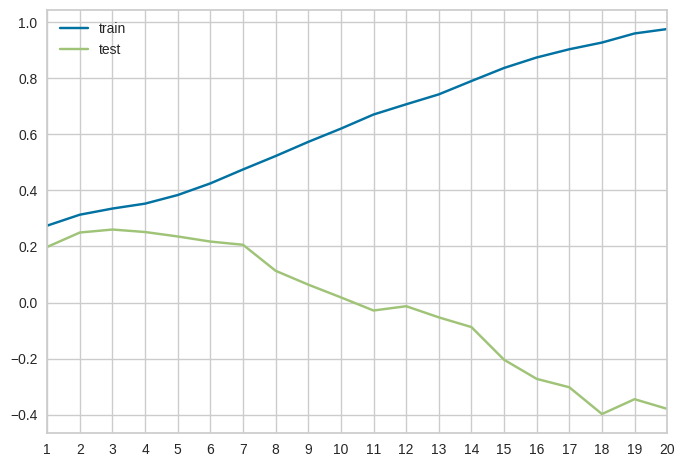

  0%|          | 0/6 [00:00<?, ?it/s]

phoneme
**Author**: Dominique Van Cappel, THOMSON-SINTRA  
**Source**: [KEEL](http://sci2s.ugr.es/keel/dataset.php?cod=105#sub2), [ELENA](https://www.elen.ucl.ac.be/neural-nets/Research/Projects/ELENA/databases/REAL/phoneme/) - 1993  
**Please cite**: None  

The aim of this dataset is to distinguish between nasal (class 0) and oral sounds (class 1). Five different attributes were chosen to characterize each vowel: they are the amplitudes of the five first harmonics AHi, normalised by the total energy Ene (integrated on all the frequencies): AHi/Ene. The phonemes are transcribed as follows: sh as in she, dcl as in dark, iy as the vowel in she, aa as the vowel in dark, and ao as the first vowel in water.  

### Source

The current dataset was formatted by the KEEL repository, but originally hosted by the [ELENA Project](https://www.elen.ucl.ac.be/neural-nets/Research/Projects/ELENA/elena.htm#stuff). The dataset originates from the European ESPRIT 5516 project: ROARS. The aim of this pro

/usr/local/lib/python3.11/dist-packages/sklearn/datasets/_openml.py:323: UserWarning: Multiple active versions of the dataset matching the name phoneme exist. Versions may be fundamentally different, returning version 1. Available versions:
- version 1, status: active
  url: https://www.openml.org/search?type=data&id=1489
- version 2, status: active
  url: https://www.openml.org/search?type=data&id=43973

  warn(warning_msg)


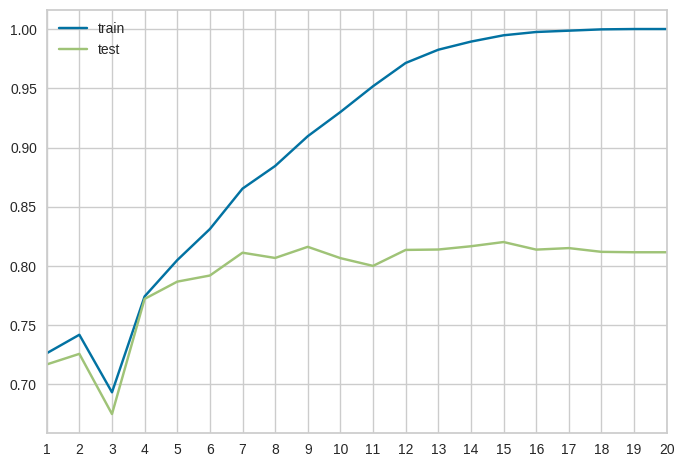

banknote-authentication
Author: Volker Lohweg (University of Applied Sciences, Ostwestfalen-Lippe)  
Source: [UCI](https://archive.ics.uci.edu/ml/datasets/banknote+authentication) - 2012  
Please cite: [UCI](https://archive.ics.uci.edu/ml/citation_policy.html) 

Dataset about distinguishing genuine and forged banknotes. Data were extracted from images that were taken from genuine and forged banknote-like specimens. For digitization, an industrial camera usually used for print inspection was used. The final images have 400x 400 pixels. Due to the object lens and distance to the investigated object gray-scale pictures with a resolution of about 660 dpi were gained. A Wavelet Transform tool was used to extract features from these images.

### Attribute Information  

V1. variance of Wavelet Transformed image (continuous)  
V2. skewness of Wavelet Transformed image (continuous)  


Class (target). Presumably 1 for genuine and 2 for forged

Downloaded from openml.org.


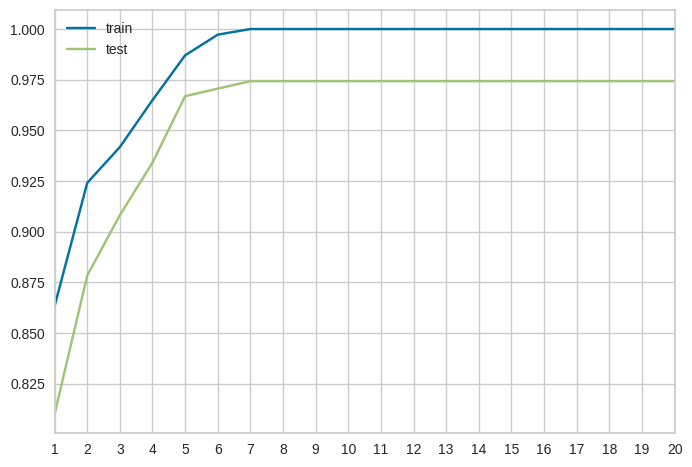

mammography
**Author**:   
  
**Source**: Unknown -   
**Please cite**:   

Mammography dataset

Past Usage:
1. Woods, K., Doss, C., Bowyer, K., Solka, J., Priebe, C.,

Downloaded from openml.org.


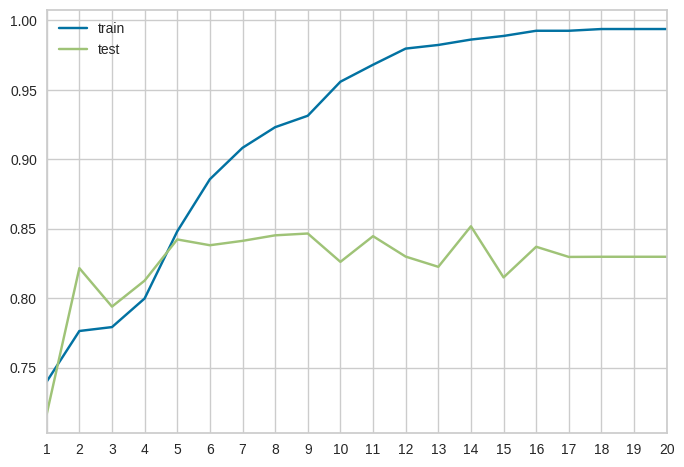

mozilla4
**Author**:   
**Source**: Unknown - Date unknown  
**Please cite**:   

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
This is a PROMISE Software Engineering Repository data set made publicly
available in order to encourage repeatable, verifiable, refutable, and/or
improvable predictive models of software engineering.

If you publish material based on PROMISE data sets then, please
follow the acknowledgment guidelines posted on the PROMISE repository
web page http://promisedata.org/repository .
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
(c) 2007  A. Gunes Koru
Contact: gkoru AT umbc DOT edu Phone: +1 (410) 455 8843
This data set is distributed under the
Creative Commons Attribution-Share Alike 3.0 License
http://creativecommons.org/licenses/by-sa/3.0/

You are free:

* to Share -- copy, distribute and transmit the work
* to Remix -- to adapt the w

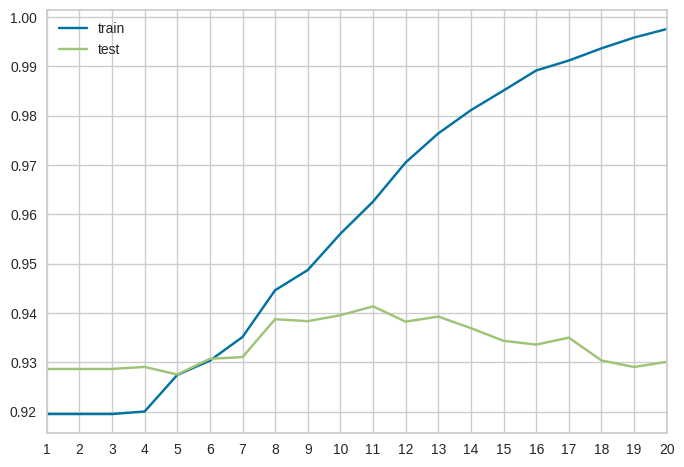

kropt
Classify a chess game based on the position of the white king, the white rook and the black king.

Downloaded from openml.org.


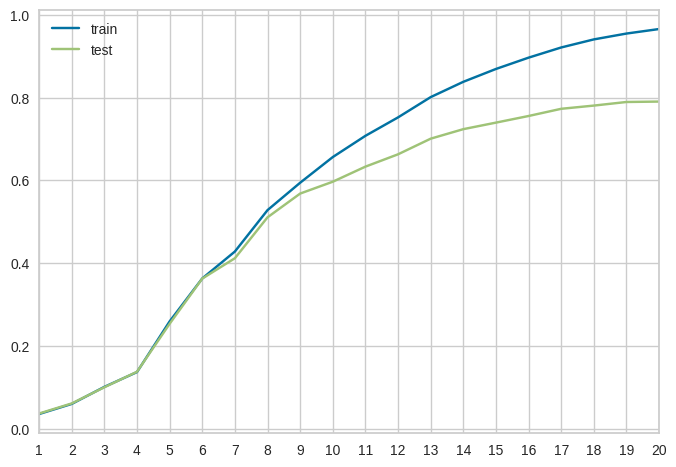

nursery
**Author**:   
**Source**: Unknown -   
**Please cite**:   

1. Title: Nursery Database
 
 2. Sources:
    (a) Creator: Vladislav Rajkovic et al. (13 experts)
    (b) Donors: Marko Bohanec   (marko.bohanec@ijs.si)
                Blaz Zupan      (blaz.zupan@ijs.si)
    (c) Date: June, 1997
 
 3. Past Usage:
 
    The hierarchical decision model, from which this dataset is
    derived, was first presented in 
 
    M. Olave, V. Rajkovic, M. Bohanec: An application for admission in
    public school systems. In (I. Th. M. Snellen and W. B. H. J. van de
    Donk and J.-P. Baquiast, editors) Expert Systems in Public
    Administration, pages 145-160. Elsevier Science Publishers (North
    Holland)}, 1989.
 
    Within machine-learning, this dataset was used for the evaluation
    of HINT (Hierarchy INduction Tool), which was proved to be able to
    completely reconstruct the original hierarchical model. This,
    together with a comparison with C4.5, is presented in
 
    B. Zupan

/usr/local/lib/python3.11/dist-packages/sklearn/datasets/_openml.py:323: UserWarning: Multiple active versions of the dataset matching the name nursery exist. Versions may be fundamentally different, returning version 1. Available versions:
- version 1, status: active
  url: https://www.openml.org/search?type=data&id=26
- version 2, status: active
  url: https://www.openml.org/search?type=data&id=959

  warn(warning_msg)


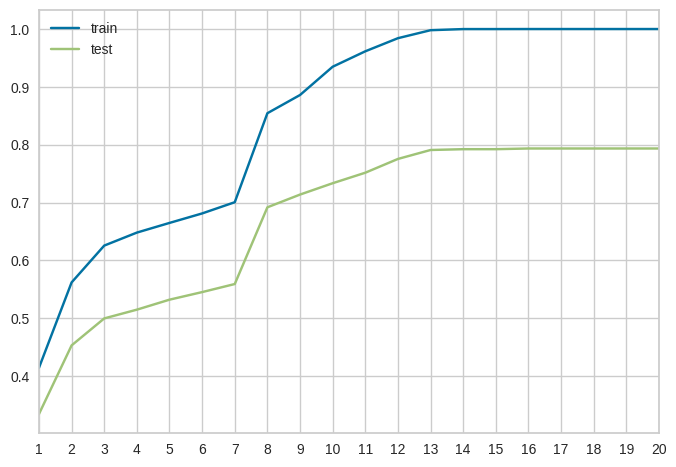

In [158]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder

def graph(dataset, reg=False):
  print(dataset.DESCR)
  df = dataset
  y = df.target
  df = dataset.frame
  target = y.name
  y = LabelEncoder().fit_transform(y)
  X = df.drop(target, axis=1)
  X = pd.get_dummies(X)
  X = SC().fit_transform(X)
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

  trains= []
  tests = []
  xs = list(range(1,21))

  for i in xs:
    if reg:
      dtc = DTR(random_state=1,max_depth=i).fit(X_train, y_train)
    else:
      dtc = DTC(random_state=1,max_depth=i).fit(X_train, y_train)
    y_train_pred = dtc.predict(X_train)
    y_pred = dtc.predict(X_test)

    if reg:
      trains.append(dtc.score(X_train, y_train))
      tests.append(dtc.score(X_test, y_test))
    else:
      trains.append(f1_score(y_train, y_train_pred,average='macro'))
      tests.append(f1_score(y_test, y_pred,average='macro'))

  plt.plot(xs,trains, label="train")
  plt.plot(xs,tests, label="test")
  plt.xlim([1,20])
  plt.xticks(xs)
  plt.legend()
  plt.grid('ON')
  plt.show()



datasets = [
    "phoneme",
    "banknote-authentication",

    "mammography",

    "mozilla4",
    "kropt",
    "nursery",

]
datasets2 = [
    "delta_ailerons",
    "electricity",
    "volcanoes-b3"
]
#dataset = fetch_openml(dataset_name, version=1, as_frame=True)
for dataset in tqdm(datasets2):
    print(dataset)
    graph(fetch_openml(dataset,as_frame=True),reg=True)

for dataset in tqdm(datasets):
    print(dataset)
    graph(fetch_openml(dataset,as_frame=True))

